In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import pywt
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from scipy.fft import fft

In [43]:
df = pd.read_csv('before.csv',names=['time','x','y','z'],header=0)

In [44]:
def slice_signal(signal, slice_length=1000):
    slices = [signal.iloc[i:i + slice_length] for i in range(0, len(signal), slice_length)]
    return slices[:-1]

In [45]:
xs = slice_signal(df['x'])

In [46]:
cA6, cD6, cD5, cD4, cD3, cD2, cD1 = pywt.wavedec(xs[102].values, 'db4', level=6)

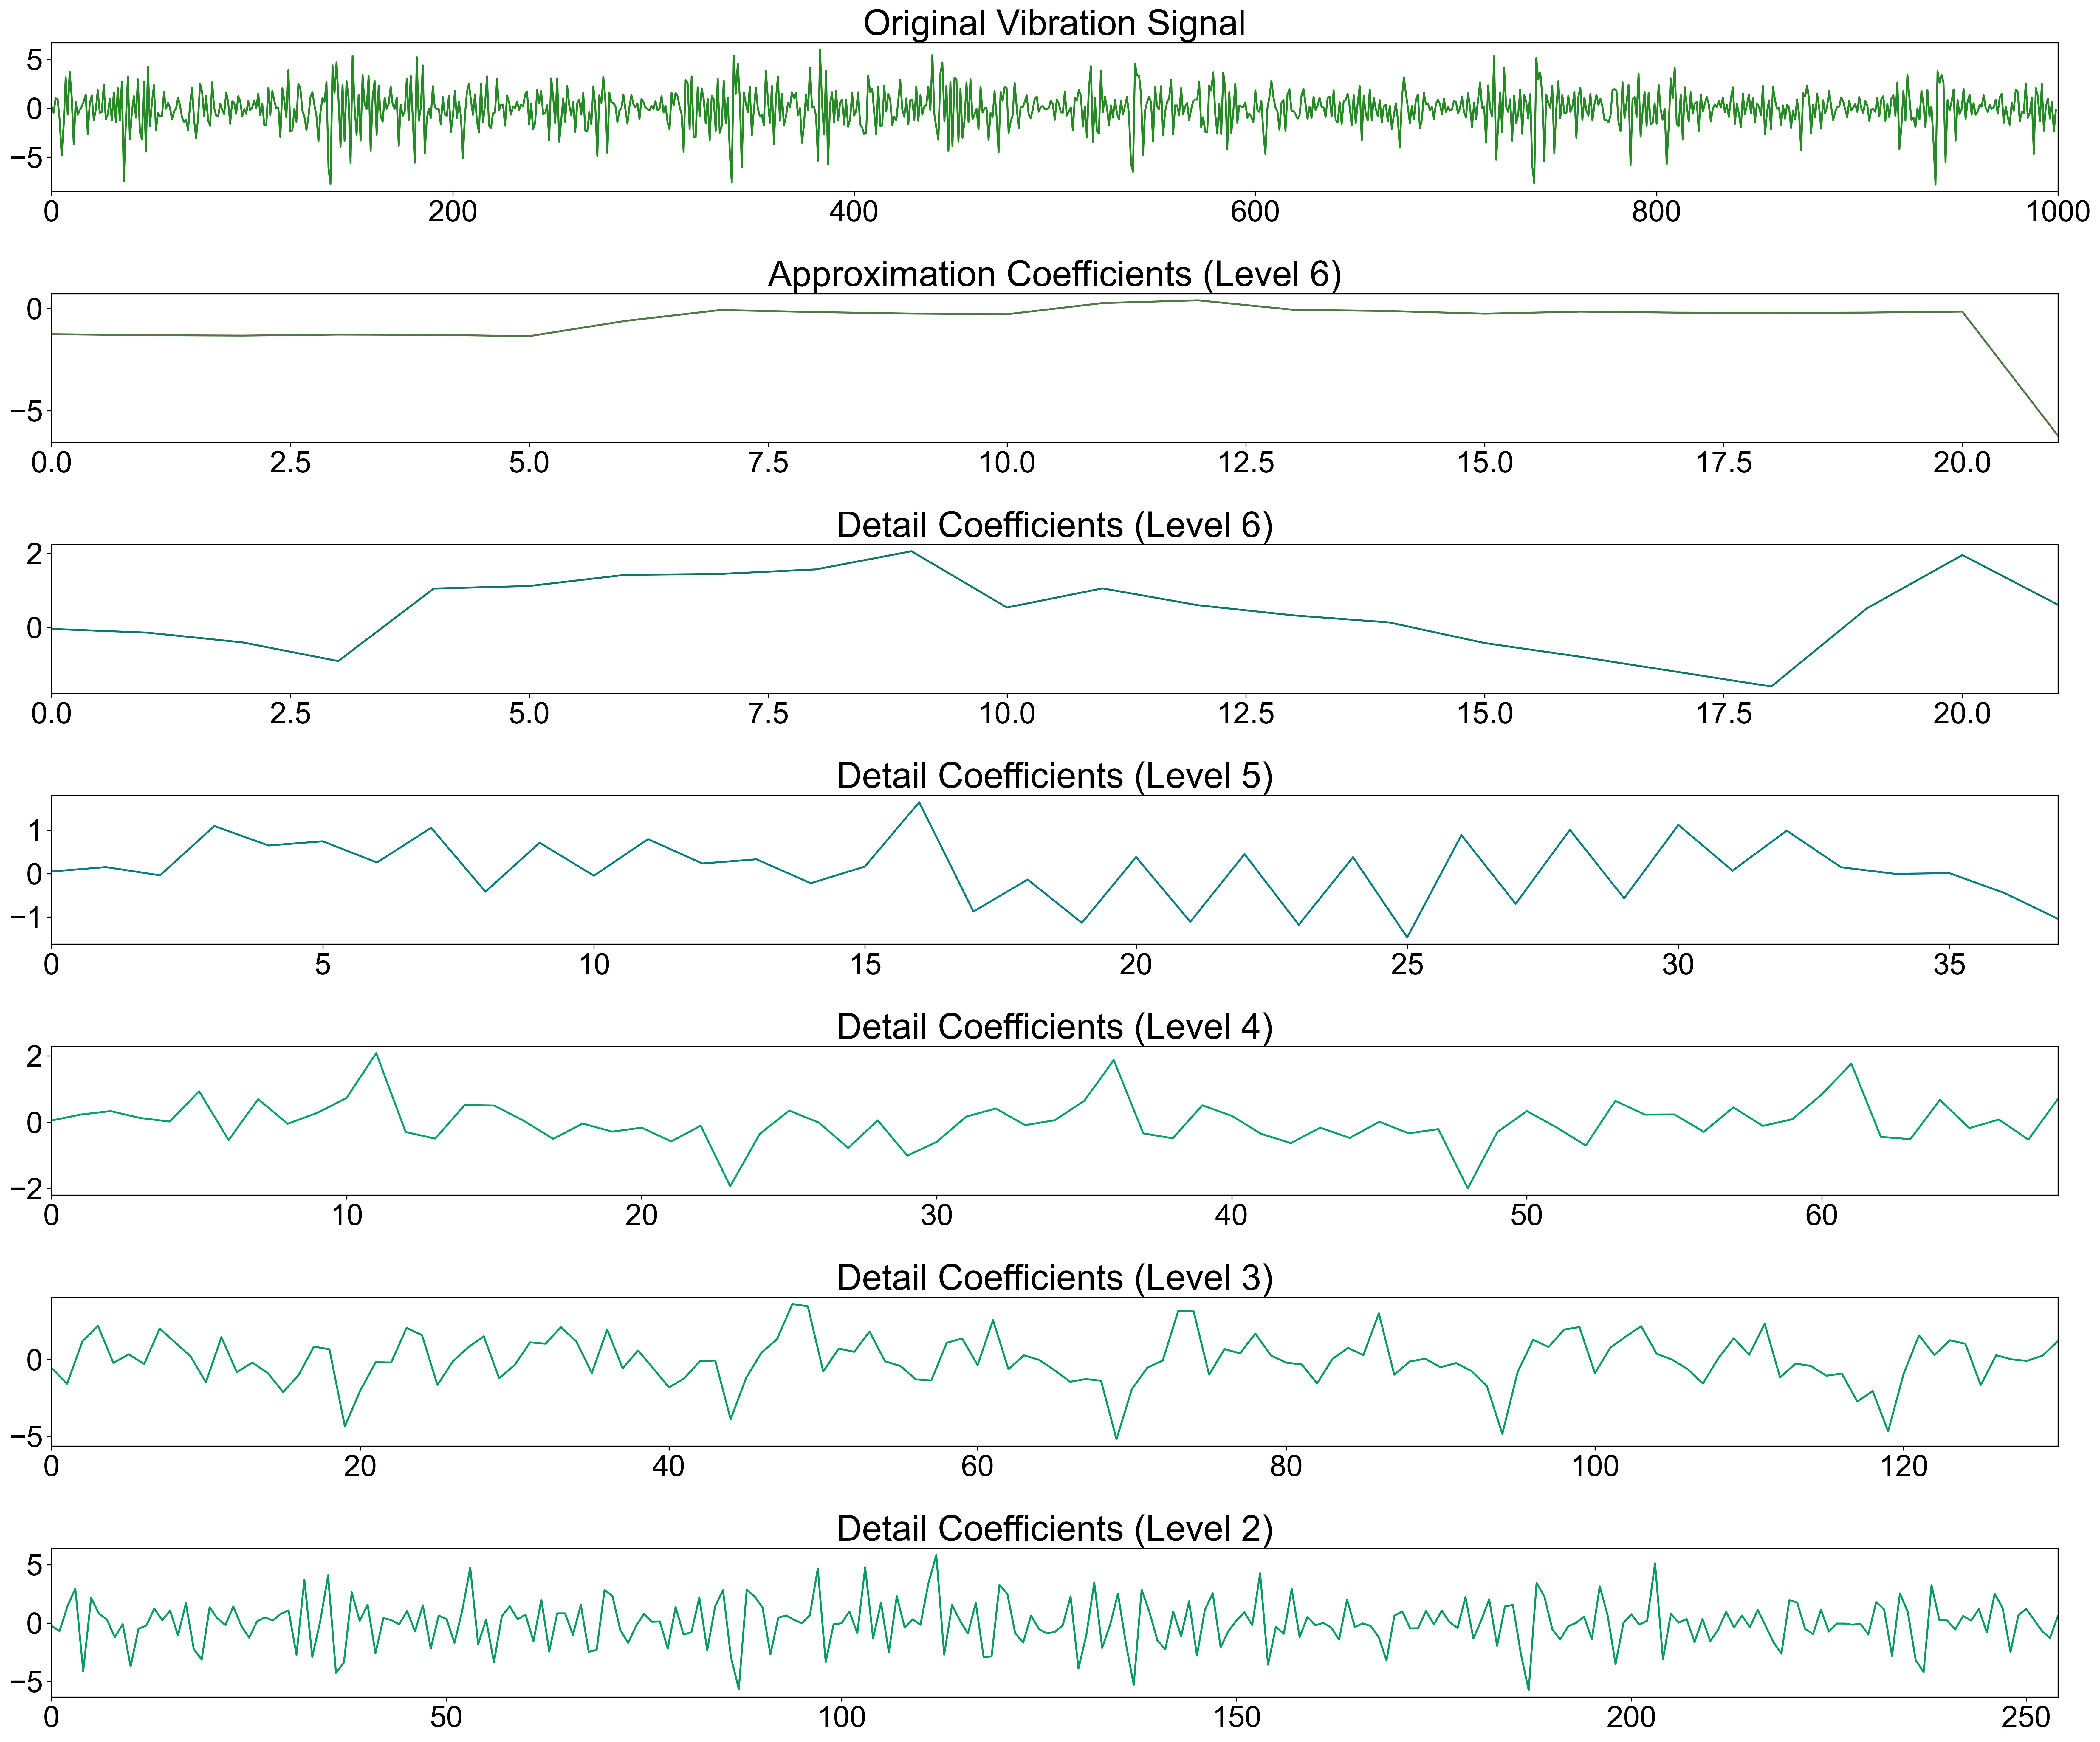

In [47]:
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 24

fig, axes = plt.subplots(7, 1, figsize=(24, 20), dpi=300)
colors = [ '#2E8B57', '#228B22', '#4F7942', '#097969', '#008080', '#00A36C', '#009E60', '#088F8F', '#2AAA8A', '#40B5AD', '#5F9EA0', '#40E0D0', '#96DED1', '#7FFFD4', '#9FE2BF', '#98FB98', '#90EE90', '#AFE1AF', '#C1E1C1', '#DFFF00', '#AAFF00', '#32CD32', '#7CFC00', '#C9CC3F', '#B4C424', '#E4D00A']

# Plot the original vibration signal
axes[0].plot(xs[102].values, color=colors[1])
axes[0].set_title("Original Vibration Signal")
axes[0].set_xlim(0, 1000)

# Plot the wavelet decomposition coefficients with decreasing darkness
axes[1].plot(cA6, color=colors[2])
axes[1].set_title("Approximation Coefficients (Level 6)")
axes[1].set_xlim(0, 21)

axes[2].plot(cD6, color=colors[3])
axes[2].set_title("Detail Coefficients (Level 6)")
axes[2].set_xlim(0, 21)

axes[3].plot(cD5, color=colors[4])
axes[3].set_title("Detail Coefficients (Level 5)")
axes[3].set_xlim(0, 37)

axes[4].plot(cD4, color=colors[5])
axes[4].set_title("Detail Coefficients (Level 4)")
axes[4].set_xlim(0, 68)

axes[5].plot(cD3, color=colors[6])
axes[5].set_title("Detail Coefficients (Level 3)")
axes[5].set_xlim(0, 130)

axes[6].plot(cD2, color=colors[6])
axes[6].set_title("Detail Coefficients (Level 2)")
axes[6].set_xlim(0, 254)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [48]:
def denoising(signal, wavelet='db4', level=6):
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    threshold = np.sqrt(2 * np.log(len(signal))) * np.median(np.abs(coeffs[-level])) / 0.6745
    denoised_coeffs = [pywt.threshold(c, threshold, mode='soft') for c in coeffs]
    return pywt.waverec(denoised_coeffs, wavelet)

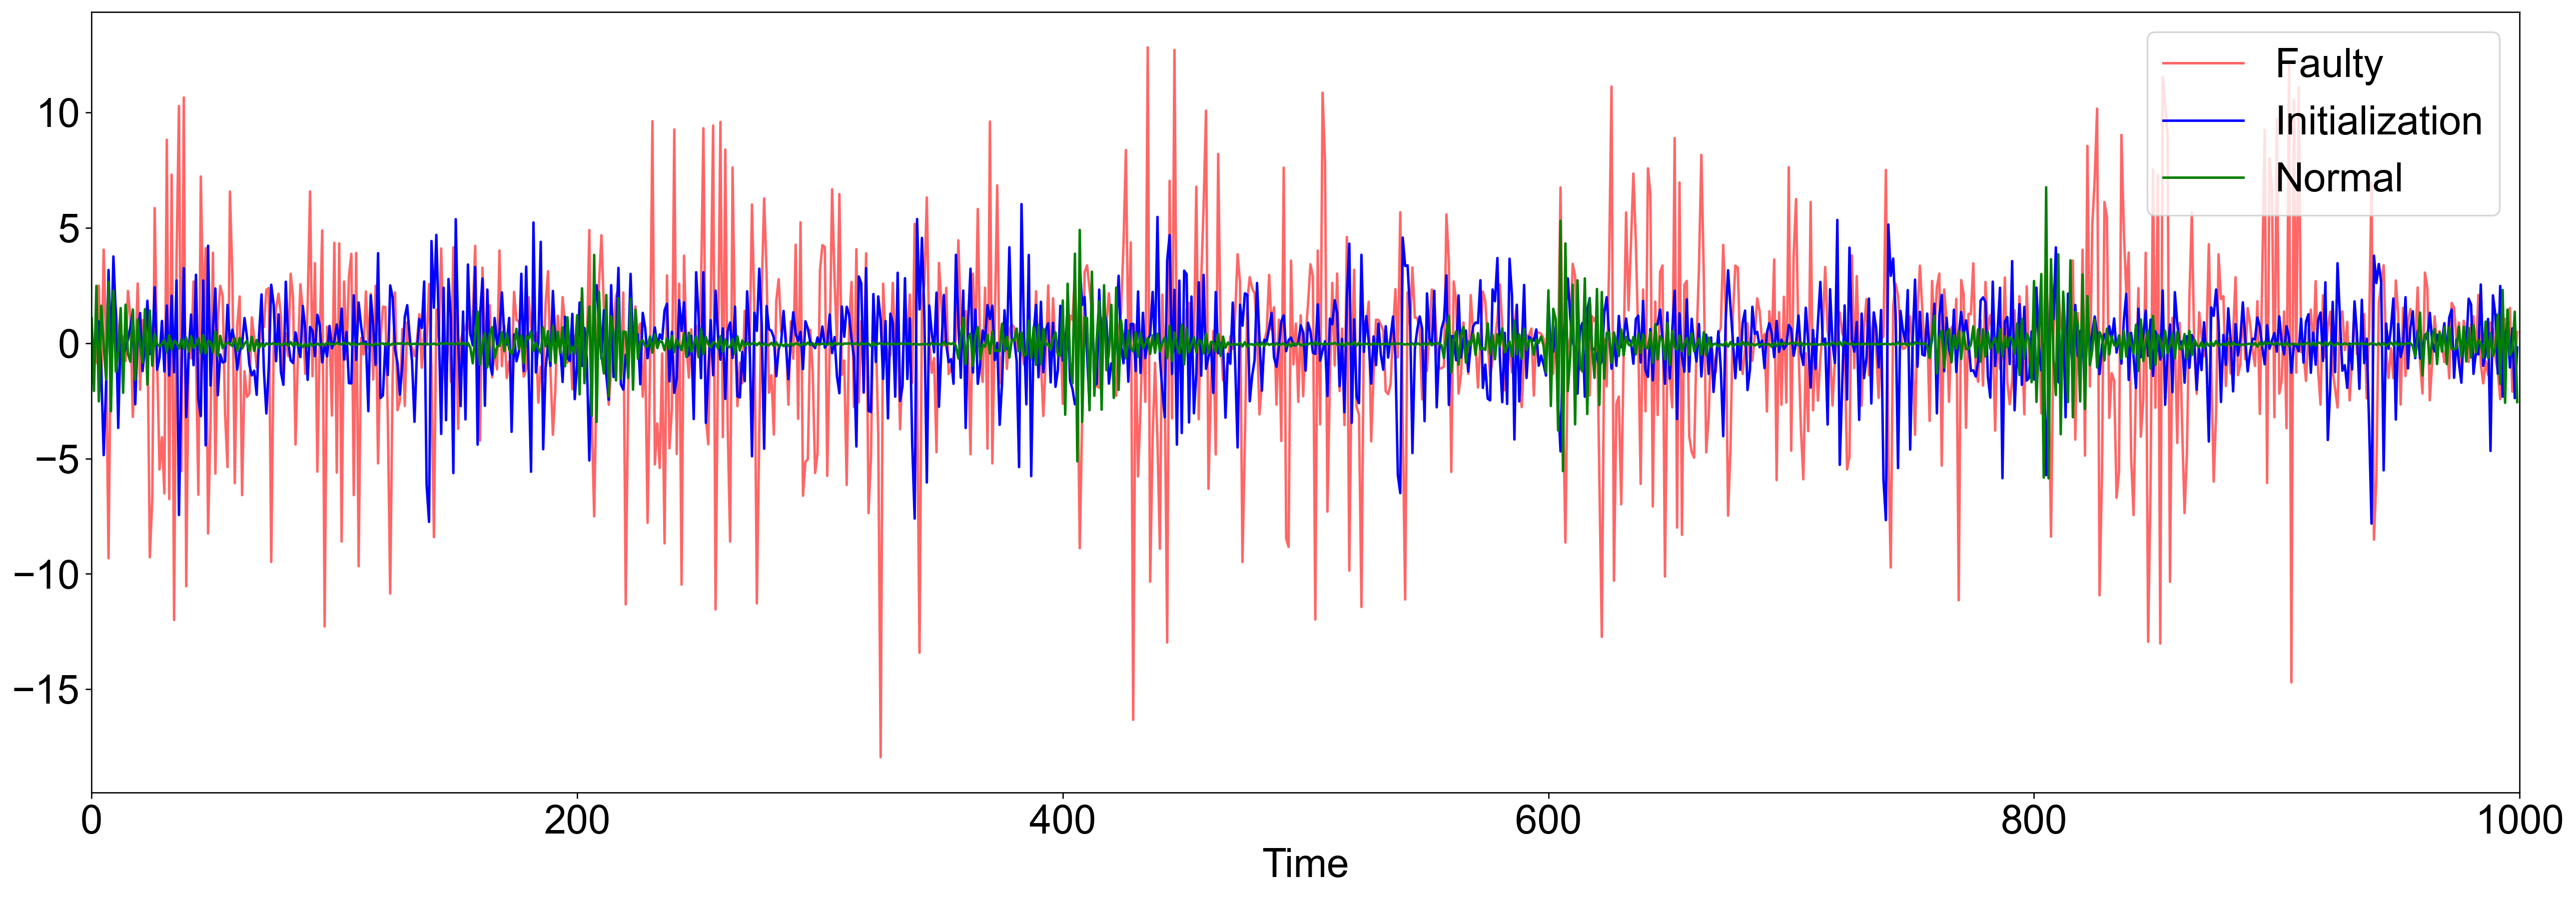

In [49]:
plt.figure(figsize=(22, 8), dpi=240)




plt.plot(range(len(xs[190])),xs[190], color='red', label='Faulty',alpha=0.6)
plt.plot(range(len(xs[190])),xs[102], color='blue', label='Initialization')
plt.plot(range(len(xs[190])),xs[40], color='green', label='Normal')
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.legend(fontsize=24,loc='upper right')
plt.xlabel('Time')
plt.xlim(0,1000)
# Show the plot
plt.tight_layout()
plt.show()

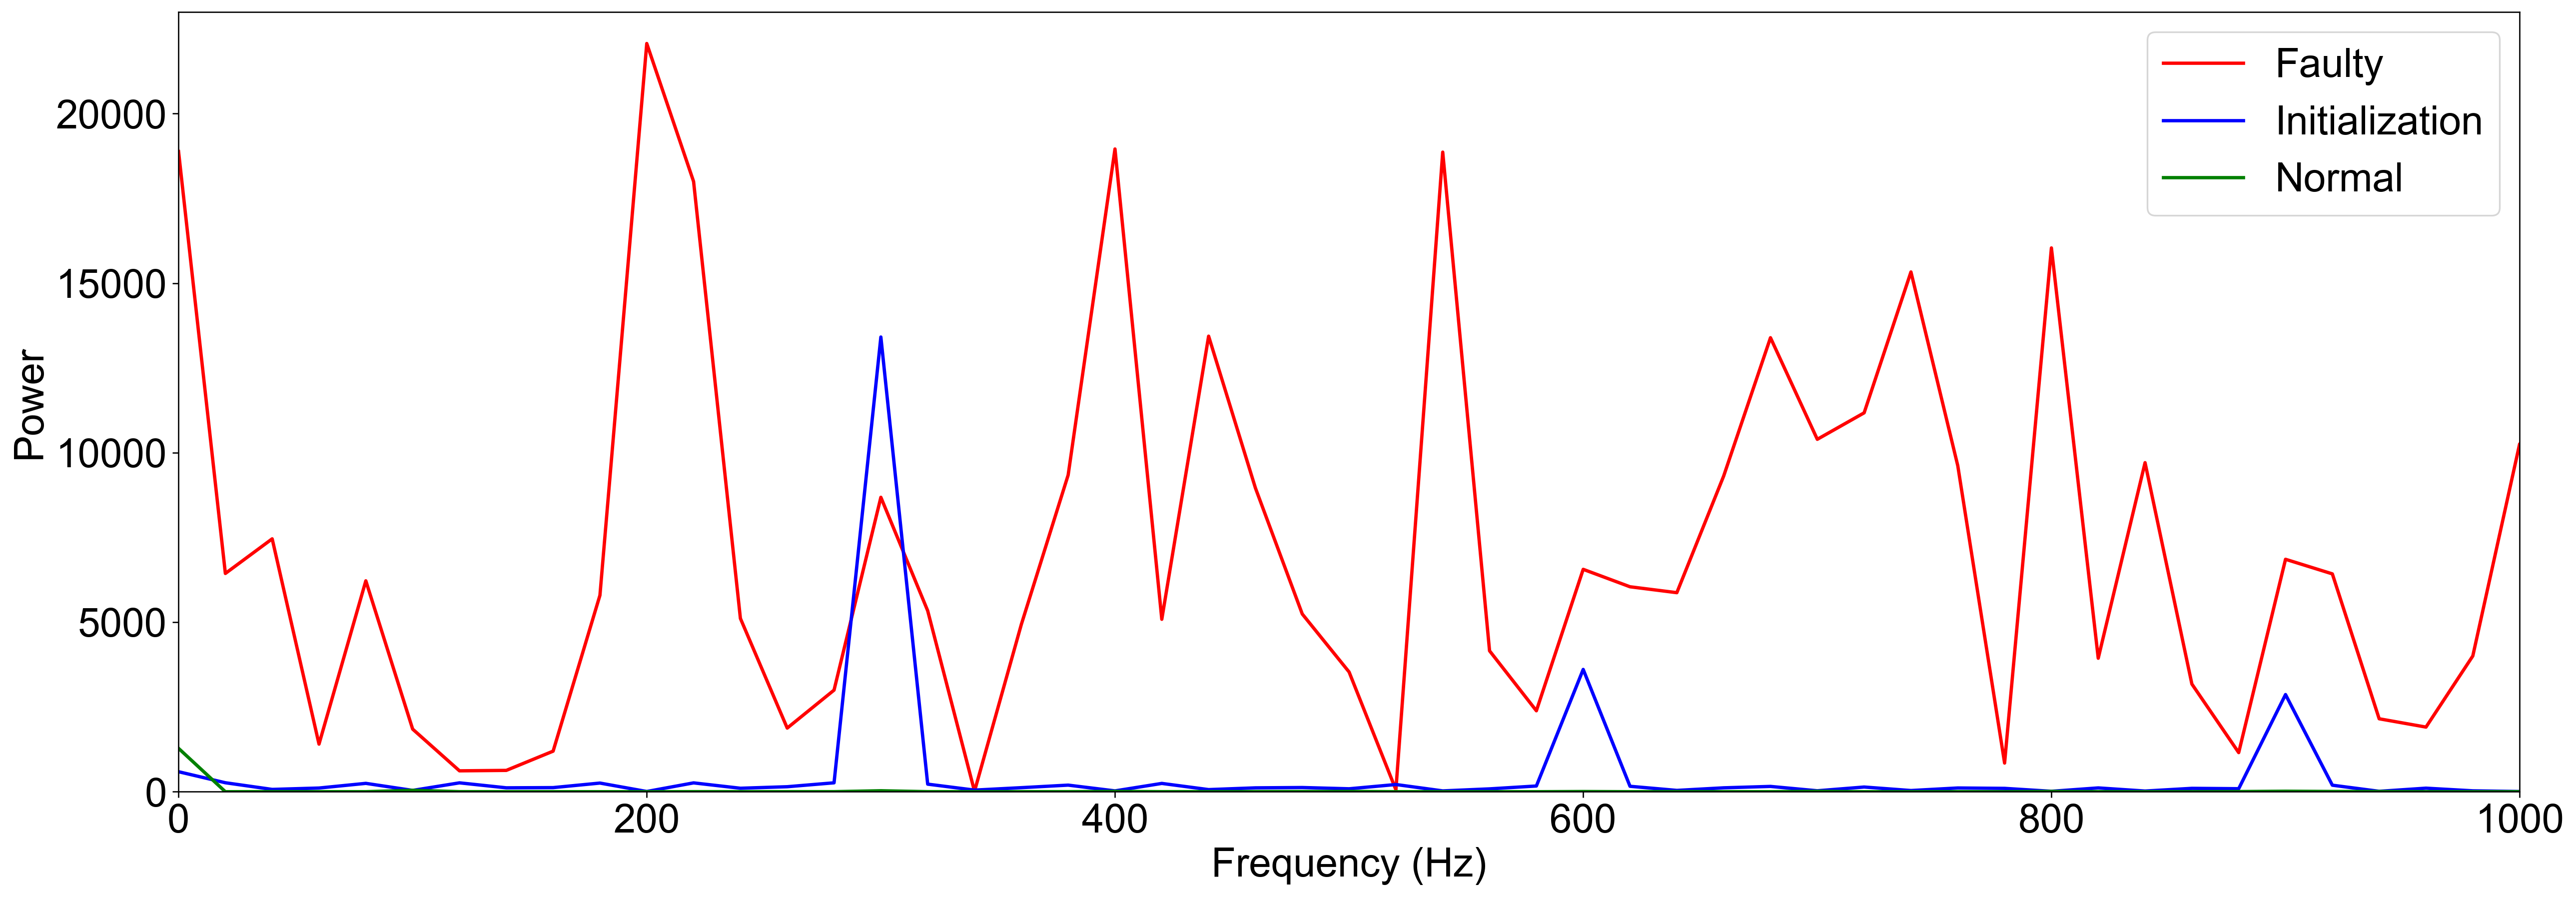

In [57]:
signal_length = 500  # Actual number of data points in your signals
sampling_freq = 10000  # 10 kHz sampling rate

plt.figure(figsize=(22, 8), dpi=240)

# Generate correct frequency axis (for 500-point signal)
freqs = np.fft.fftfreq(signal_length, d=1/sampling_freq)[:signal_length//2]

# Plotting function
def plot_spectrum(signal, color, label):
    fft_vals = np.fft.fft(signal)
    power = np.abs(fft_vals) ** 2
    plt.plot(freqs, power[:signal_length//2], color=color, label=label, linewidth=2)

# Plot all signals
plot_spectrum(xs[190], 'red', 'Faulty')
plot_spectrum(xs[102], 'blue', 'Initialization')
plot_spectrum(xs[40], 'green', 'Normal')

# Formatting
plt.legend(fontsize=24, loc='upper right')
plt.xlabel('Frequency (Hz)', fontsize=24)
plt.xlim(0, 1000)  # Focus on 0-500 Hz range
plt.ylim(0, 23000)  # Focus on 0-500 Hz range
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.ylabel('Power', fontsize=24)
plt.tight_layout()
plt.show()